# Can a 2K language model read 4K tokens?

**A guided context-extension experiment · SmolLM-135M · fixed pretrained weights**

A model trained for short inputs may accept a longer input yet make much worse
predictions. We will test whether changing its positional encoding with **YaRN**
helps, while keeping its learned weights and prediction targets fixed.

Read the explanations and recorded results first. Run the code when you want to
repeat the experiment on a CUDA GPU. Nothing in this notebook trains a model.


## 1. What was the assignment?

G5's Week 3 task was to **write `docs/long_context_plan.md` and test the
context-extension step on a small model**. The assigned review date is
**19 November 2026**. The purpose is to give TSAI evidence for a later context
schedule decision, before changing the capstone model's production settings.

| Required work | What was delivered | Where this notebook fits |
|---|---|---|
| Explain a context-extension proposal | Method, settings, trade-offs and follow-up plan | Teaches the reasoning behind that proposal |
| Run a small-model test and keep evidence | A matched 2K/4K check on G5's frozen corpus, using eager attention and the full output head | Contains the earlier **WikiText pilot**, with SDPA and a tail-only output head |
| Review whether to adopt the proposal | Remains a TSAI/team decision | Supplies bounded evidence, not production approval |

The [submission plan](../docs/long_context_plan.md) and
[primary test log](../results/context_extension/TEST_LOG.md) contain the
class-corpus result. **This notebook's WikiText losses and timings are separate.**
The [Lab 3 briefing](https://axiom.theschoolofai.in/widgets/cap_lab3_briefing.html)
and [owner allocation](https://axiom.theschoolofai.in/courses/cmq97i5kn032208o8xu5dab4q?chat=cmvkupxl427gl09l7rv9m4fwy&msg=cmwg7xjek0ji109o5b03mxagt)
are the assignment sources. This notebook addresses the G5 task; the G6 kernel
correctness rotation is a separate deliverable.


## 2. The concepts we need

| Term | Meaning in this experiment |
|---|---|
| Token | One tokenizer-produced unit of text; it is not necessarily a word |
| Context window | The number of input tokens the model reads in one forward pass |
| Checkpoint | A saved set of learned model weights; ours stays fixed |
| RoPE | Rotary Position Embeddings: position-dependent rotations of attention queries and keys |
| Context extension | Adapting a short-context model for longer inputs, then checking whether its predictions remain useful |
| NLL | Negative log-likelihood: the average penalty for assigning low probability to the correct next token |

**Why not just raise the length limit?** Allowing a 4K tensor removes a software
limit. It does not teach a 2K model how to handle the unfamiliar positional
patterns. We need to measure the resulting prediction quality.

RoPE uses several rotation frequencies. Nearby tokens have small relative
position differences; distant tokens can expose rotations outside the range
seen in training. The method choice below changes those positional signals.


## 3. What choices did we have?

| Choice | What changes | Why consider it? | Trade-off |
|---|---|---|---|
| Unscaled extrapolation | Feed 4K tokens with the original RoPE settings | The simplest baseline | May lose quality beyond the original window |
| Position interpolation | Divide positions, equivalently all rotary frequencies, by the length factor | A simple scaling baseline | Alters local and long-range rotations together |
| NTK-aware scaling | Change the RoPE frequency schedule through its base | A frequency-sensitive alternative | Static and dynamic variants must be specified |
| **YaRN** | Blend frequency bands and adjust rotary amplitude | A concrete, configurable extension candidate | Adds settings that need independent checks |
| Continued training | Update weights on a suitable long-context mixture, usually alongside a positional method | Can adapt the model to the new window | Requires an agreed data mixture, budget and short-context checks |

We chose **static YaRN ×2** for one controlled small-model trial. This is a
candidate selection, not a measured win against interpolation or NTK scaling:
those alternatives are **not implemented or scored here**. No continued
training is performed. See the [YaRN paper](https://arxiv.org/abs/2309.00071),
Sections 2–3, for the positional methods and their assumptions.


## 4. What exactly will we compare?

Use the original **SmolLM-135M**, whose configured window is 2,048 tokens.
It is small enough to rerun quickly and uses RoPE, so extending it to 4,096 is
a meaningful beyond-window test. A newer model already configured for 4K or
more would not test this particular 2K-to-4K retrofit.

Select three complete WikiText test articles before looking at their losses.
Keep the first 4,096 token IDs from each article. The short input is the exact
last 2,048 IDs of that same window. Every run scores the **same last 512 targets**.

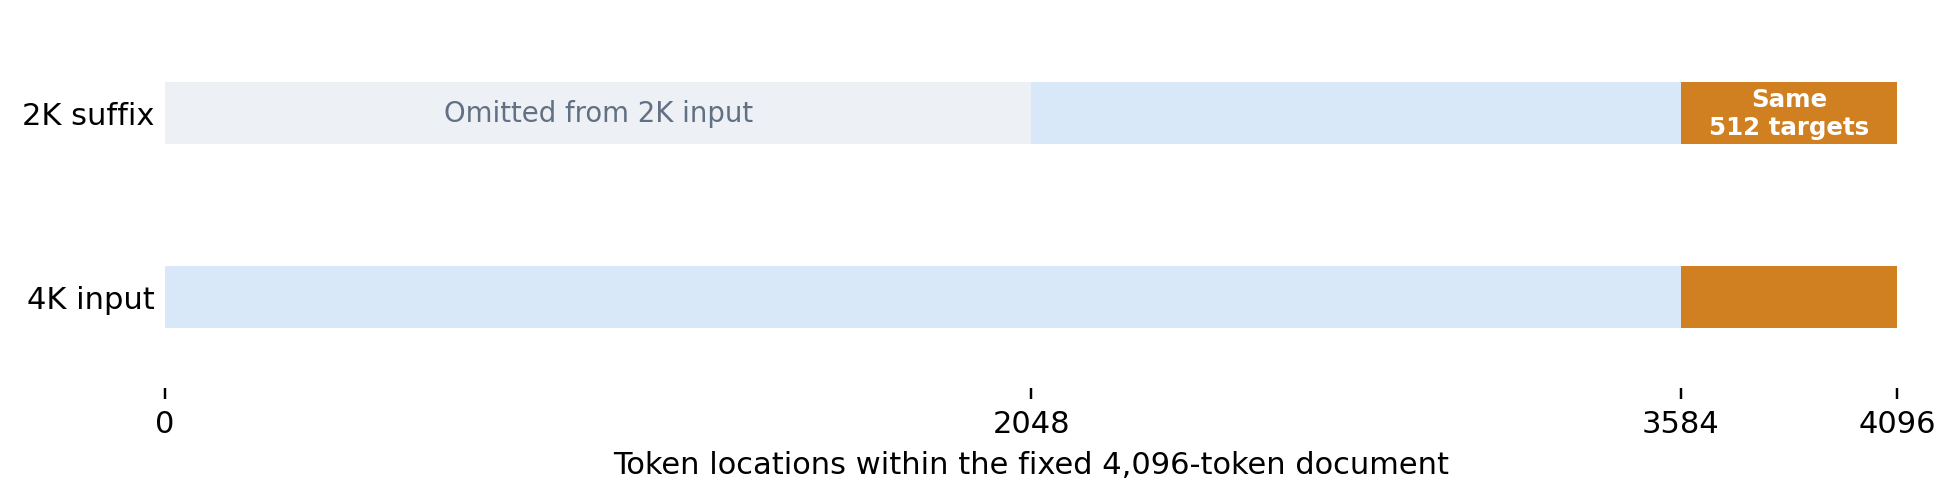

The figure's coordinates locate tokens in the fixed article window. Model
position IDs restart at zero inside each independent input. Blue tokens are
available as preceding context; yellow tokens are the common prediction targets.
The short input contains 1,536 preceding tokens plus the 512 target tokens;
the long input contains 3,584 plus the same 512.

| Run | Input length | Positional method | Question answered |
|---|---:|---|---|
| A | 2,048 | Original RoPE | How good is the native-window reference? |
| B | 4,096 | Original RoPE | What happens if we simply extrapolate? |
| C | 4,096 | YaRN ×2 | Does the positional retrofit improve unscaled 4K? |
| D | 2,048 | The **same** YaRN ×2 settings as C | Does the retrofit change short-window quality? |

**C−B** compares positional methods at 4K. **D−A** measures short-window
sensitivity. **C−D** holds YaRN fixed and measures the extra input prefix.
**C−A** changes both method and length, so it cannot isolate the prefix's effect.


## 5. Recorded results: read before running

These measurements come from the original GPU run on **18 November 2026 IST**
(`2026-11-17T19:29:18.881325+00:00` UTC). They are a saved snapshot, not outputs
from a new execution of this converted notebook. This historical snapshot remains fixed.
Fresh results appear below the code cells when this notebook is executed;
the final manifest records their timestamp and runtime.

| Run | Rotary method | Input tokens | Mean NLL ↓ | Perplexity ↓ |
|---|---|---:|---:|---:|
| A | Original RoPE | 2048 | 2.470164 | 11.824388 |
| B | Original RoPE | 4096 | 6.693264 | 806.952112 |
| C | YaRN ×2 | 4096 | 2.482160 | 11.967088 |
| D | YaRN ×2 | 2048 | 2.470355 | 11.826650 |

YaRN recovers most of the loss caused by using ordinary 2K RoPE at 4K.
Holding YaRN fixed, 4K minus 2K is **+0.011805 nats/token**: the extra prefix
does not improve mean loss on these three suffixes. This does not establish
a general limit on long-context usefulness.

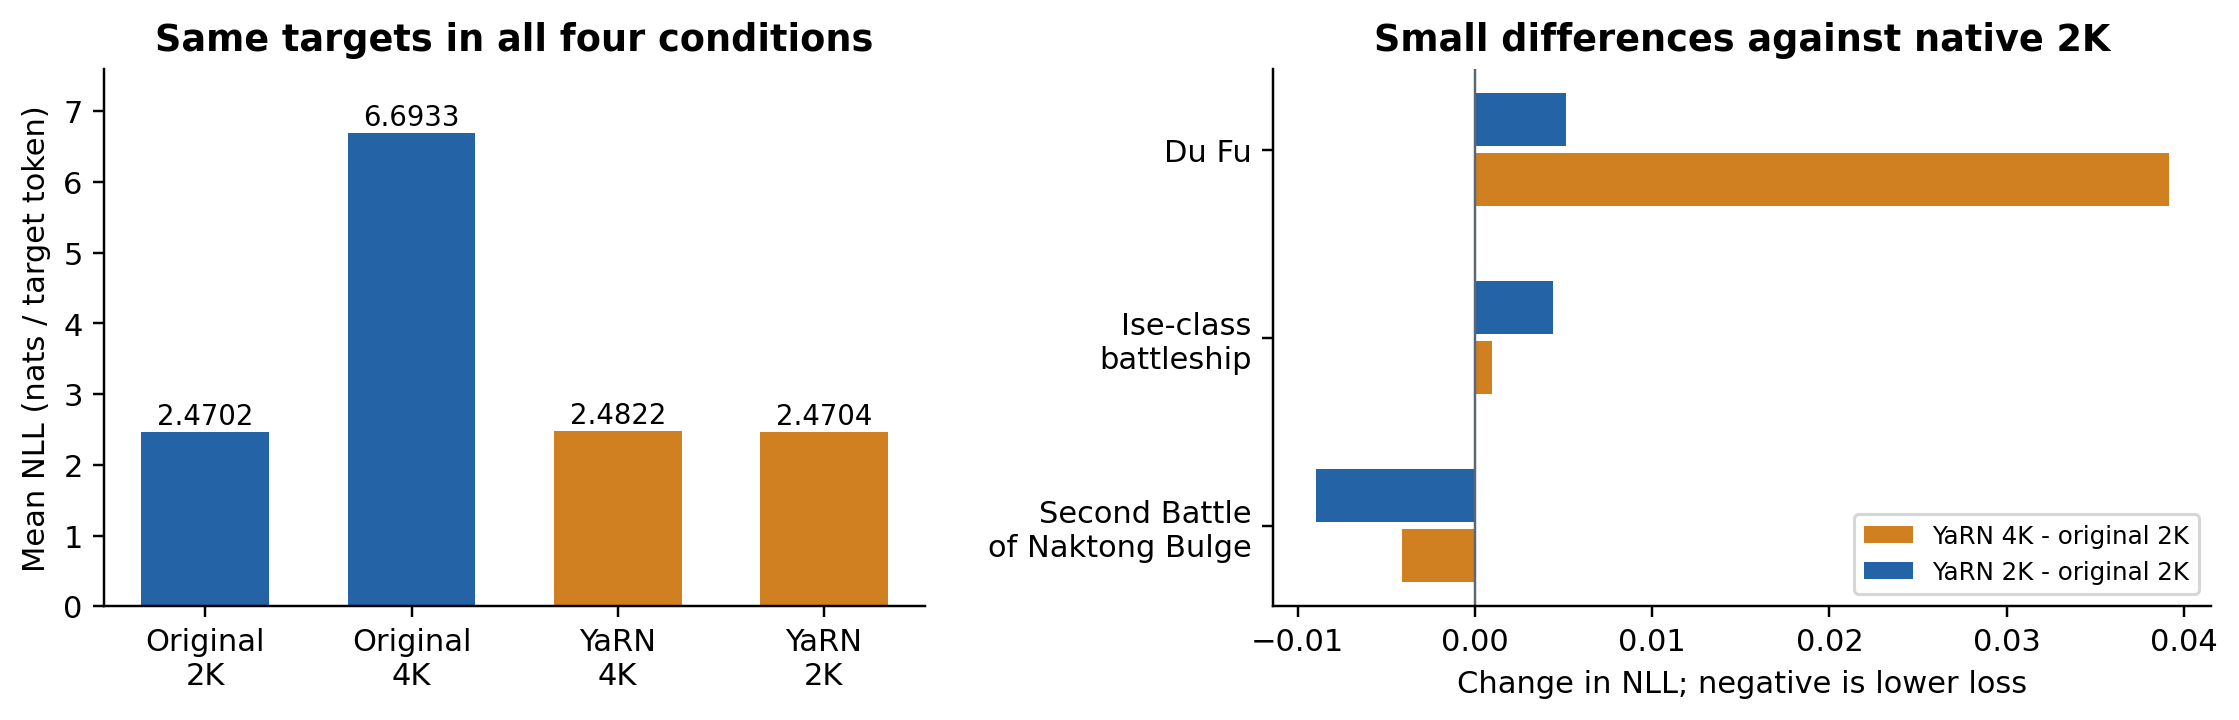

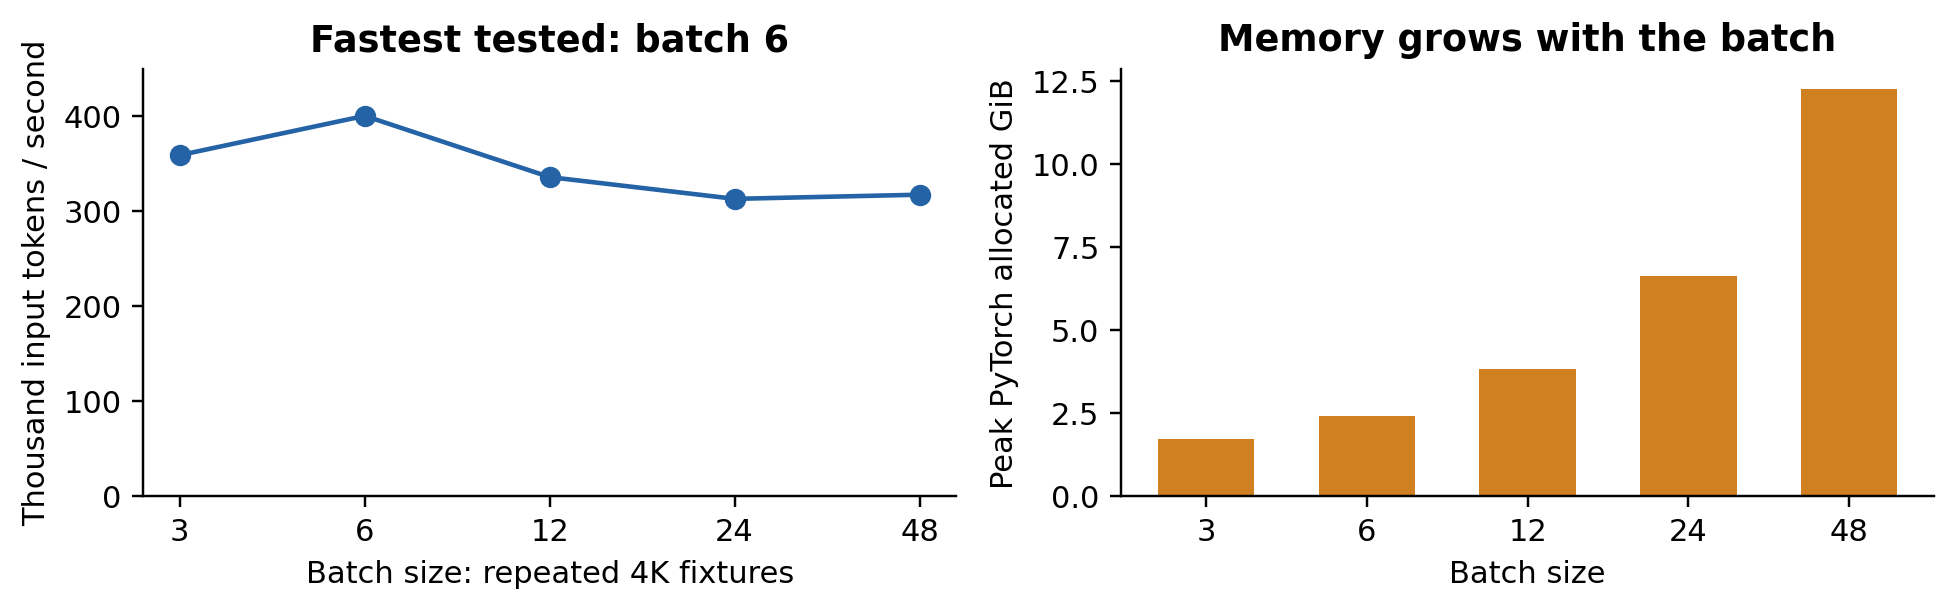

The batch sweep repeats these same three fixtures; it adds no quality samples.
Fastest tested batch: **6**, about **400,418 input tokens/s**, with **2,475.6 MiB**
peak allocated memory. These are forward-plus-tail-loss measurements.
The saved CSVs and full timing scope are in the [pilot log](../results/context_extension/PILOT_TEST_LOG.md).

The following sections explain and reproduce the computations behind this snapshot.


## 6. Run setup

Use **Python 3.13**, a CUDA GPU with BF16 support, and a compatible driver.
Install the adjacent `requirements-context-extension.txt`, select that Python
kernel, then Run All. The first run downloads the pinned public model and data.
The batch sweep includes 48 repeated inputs; it was tested on an approximately
95-GiB GPU. For a fresh run on a smaller GPU, change the sweep deliberately and
record that difference rather than comparing it with the original timings.

Downloads, model loading and warm-up are excluded from the CUDA timings.
New evidence goes to `out/context_extension_pilot/` beneath the kernel's working
directory. It does not overwrite the committed measurement snapshot.


In [1]:
from pathlib import Path
import copy
import datetime
import hashlib
import importlib.metadata
import json
import math
import os
import platform

import altair as alt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
import vl_convert as vlc
from datasets import load_dataset
from huggingface_hub.utils import disable_progress_bars
from IPython.display import Image, JSON, display
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

# Keep the original experiment's seed and numerical runtime settings.
disable_progress_bars()
torch.manual_seed(1234)
torch.set_num_threads(16)
torch.set_float32_matmul_precision("highest")
alt.theme.enable("default")


def chart_image(chart):
    """Render a chart as a static PNG, including in GitHub's notebook viewer."""
    return Image(data=vlc.vegalite_to_png(chart.to_dict(), scale=2))


In [2]:
MODEL_ID = "HuggingFaceTB/SmolLM-135M"
MODEL_REVISION = "1d461723eec654e65efdc40cf49301c89c0c92f4"
DATASET_ID = "Salesforce/wikitext"
DATASET_REVISION = "b08601e04326c79dfdd32d625aee71d232d685c3"

NATIVE_LENGTH = 2048
LONG_LENGTH = 4096
TAIL_LENGTH = 512  # The common final targets we score in every run.
DOCUMENT_COUNT = 3
TIMING_REPEATS = 3
BATCH_SIZES = [3, 6, 12, 24, 48]
DEVICE = "cuda"
DTYPE = torch.bfloat16
ARTIFACT_DIR = Path.cwd() / "out" / "context_extension_pilot"

assert torch.cuda.is_available(), "Run the experiment in a CUDA GPU session."
assert torch.cuda.is_bf16_supported(), "The recorded comparison uses BF16."
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

hardware = {
    "gpu": torch.cuda.get_device_name(0),
    "vram_gib": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2),
    "visible_vcpus": len(os.sched_getaffinity(0)),
    "visible_ram_gib": round(
        os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1
    ),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "cuda": torch.version.cuda,
}
for label, filename in [
    ("container_memory_limit", "memory.max"),
    ("container_cpu_quota", "cpu.max"),
]:
    limit_file = Path("/sys/fs/cgroup") / filename
    if limit_file.exists():
        hardware[label] = limit_file.read_text().strip()

display(pd.DataFrame(hardware.items(), columns=["Runtime property", "Observed value"]))


,Runtime property,Observed value
0,gpu,NVIDIA RTX PRO 6000 Blackwell Server Edition
1,vram_gib,94.97
2,visible_vcpus,20
3,visible_ram_gib,160.0
4,python,3.13.11
5,torch,2.11.0+cu130
6,transformers,5.14.1
7,cuda,13.0


## 7. Load identical weights with two positional configurations

Both copies load the same checkpoint revision. `eval()` disables dropout;
`torch.inference_mode()` in the scoring function disables gradient recording.
There is no optimizer and no backward pass.

We change the YaRN configuration's allowed length to 4K while explicitly keeping
**2K as the original reference length**. That distinction matters: the scaling
method must know the window being extended. SDPA is PyTorch's scaled-dot-product
attention backend; it is used only in this exploratory pilot.


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
base_config = AutoConfig.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
assert base_config.max_position_embeddings == NATIVE_LENGTH
assert base_config.num_attention_heads == 9
assert base_config.num_key_value_heads == 3

yarn_config = copy.deepcopy(base_config)
yarn_config.max_position_embeddings = LONG_LENGTH
yarn_config.rope_parameters = {
    "rope_type": "yarn",
    "rope_theta": 10000.0,
    "factor": 2.0,
    "original_max_position_embeddings": NATIVE_LENGTH,
    "beta_fast": 32.0,
    "beta_slow": 1.0,
}

native_model = (
    AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=base_config,
        dtype=DTYPE,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval()
)

yarn_model = (
    AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=yarn_config,
        dtype=DTYPE,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval()
)

models = {"Original RoPE": native_model, "YaRN ×2": yarn_model}
parameter_count = sum(parameter.numel() for parameter in native_model.parameters())
print(f"Each model has {parameter_count:,} pretrained parameters.")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Each model has 134,515,008 pretrained parameters.


## 8. Select the articles without using their scores

WikiText stores article text across rows. A top-level heading starts a new
article; subheadings stay inside the article. We finish assembling each article
before deciding whether it has at least 4K tokens. This avoids inventing long
inputs by repeating text or joining unrelated documents.

The first three qualifying test articles are selected deterministically. We
save text and token hashes so a later run can check the exact inputs.
Pretraining overlap with this older Wikipedia-derived corpus is unknown.


In [4]:
def select_documents(rows, tokenizer, count, length):
    """Return the first count complete articles with at least length tokens."""
    selected = []
    article_title, paragraphs = ("", [])

    def consider(title, paragraphs):
        text = "\n".join(paragraphs).strip()
        ids = tokenizer(text, add_special_tokens=False, truncation=False)["input_ids"]
        if title and len(ids) >= length:
            selected.append(
                {
                    "title": title,
                    "available_tokens": len(ids),
                    "ids": ids[:length],
                    "text_sha256": hashlib.sha256(text.encode()).hexdigest(),
                    "tokens_sha256": hashlib.sha256(
                        json.dumps(ids[:length]).encode()
                    ).hexdigest(),
                }
            )

    # Check an article only after reaching its next top-level heading.
    for row in rows:
        line = row["text"].strip()
        new_article = (
            line.startswith("= ")
            and line.endswith(" =")
            and (not line.startswith("= ="))
        )
        if new_article:
            consider(article_title, paragraphs)
            if len(selected) == count:
                return selected
            article_title, paragraphs = (line.strip("= ").strip(), [])
        elif line:
            paragraphs.append(line)
    consider(article_title, paragraphs)
    assert (
        len(selected) >= count
    ), "Insufficient complete long articles in the selected split."
    return selected[:count]


In [5]:
evaluation_dataset = load_dataset(
    "parquet",
    data_files={
        "test": (
            f"hf://datasets/{DATASET_ID}@{DATASET_REVISION}/"
            "wikitext-103-raw-v1/test-00000-of-00001.parquet"
        )
    },
    split="test",
)
documents = select_documents(evaluation_dataset, tokenizer, DOCUMENT_COUNT, LONG_LENGTH)

# Shape: [documents, input tokens]. Both windows end on the same token IDs.
long_inputs = torch.tensor(
    [document["ids"] for document in documents], dtype=torch.long, device=DEVICE
)
short_inputs = long_inputs[:, -NATIVE_LENGTH:].contiguous()
target_ids = long_inputs[:, -TAIL_LENGTH:]
assert torch.equal(target_ids, short_inputs[:, -TAIL_LENGTH:])

document_table = pd.DataFrame(
    [
        {
            "Article": document["title"],
            "Available tokens": document["available_tokens"],
            "Long-input tokens": LONG_LENGTH,
            "Token SHA256 prefix": document["tokens_sha256"][:16],
        }
        for document in documents
    ]
)
display(document_table)


,Article,Available tokens,Long-input tokens,Token SHA256 prefix
0,Du Fu,5464,4096,016d8c4c42b97e03
1,Ise @-@ class battleship,9611,4096,1fa159379ba94005
2,Second Battle of Naktong Bulge,12495,4096,7b59ff5b37fa48dd


## 9. Score next-token predictions, not the tokens at the same positions

At position $t$, a causal language model predicts token $t+1$. If the final
512 target IDs start at input index $T-512$, their prediction rows start one
position earlier, at $T-513$.

| Quantity | Shape or indices |
|---|---|
| Input IDs | `[batch, T]`; all 2K or 4K tokens pass through the transformer |
| Requested final logit rows | `[batch, 513, vocabulary]` |
| Prediction logits | Drop the final row → `[batch, 512, vocabulary]` |
| Correct target IDs | Last 512 input IDs → `[batch, 512]` |
| Returned losses | `[batch, 512]`, one loss per target token |

We project only the final 513 hidden rows into vocabulary logits. This saves
output-head work; **it does not truncate the context entering attention**.
The discarded final row would predict a token beyond our input, so it has no
matching target here. A separate full-head check below verifies the alignment.


In [6]:
@torch.inference_mode()
def score_tail(model, inputs, tail_length=TAIL_LENGTH):
    """Return next-token NLL for the same final targets; keep every input token."""
    # Request one extra logit row to account for the next-token shift.
    outputs = model(input_ids=inputs, use_cache=False, logits_to_keep=tail_length + 1)
    # [batch, tail + 1, vocabulary] -> [batch, tail, vocabulary]
    prediction_logits = outputs.logits[:, :-1, :].float()
    # These are the identical target IDs in the 2K and 4K inputs.
    targets = inputs[:, -tail_length:]
    losses = F.cross_entropy(
        prediction_logits.reshape(-1, prediction_logits.shape[-1]),
        targets.reshape(-1),
        reduction="none",
    ).view(inputs.shape[0], tail_length)
    return losses


### What do NLL and perplexity mean?

For each correct target $y_i$, the model assigns a probability $p_i$.
Its loss is $-\log(p_i)$: confident correct predictions have smaller loss.

$$\mathrm{NLL}=\frac{1}{N}\sum_i-\log(p_i),\qquad
\mathrm{perplexity}=\exp(\mathrm{NLL}).$$

Every article contributes exactly 512 targets, so averaging the three article
NLLs equals averaging all 1,536 token losses. We exponentiate **after** averaging;
we do not average article perplexities. These token metrics are valid within
this one tokenizer and are not interchangeable with the team's bits-per-byte.


## 10. Check the experiment before interpreting its results

The checks answer three questions: are the weights and targets matched, did
YaRN resolve to the intended settings, and is the optimized scorer aligned?
A check failure stops execution rather than leaving a plausible-looking chart.


In [7]:
checks = []


def check(name, condition, detail):
    """Stop on a failed assumption and retain a readable receipt on success."""
    assert bool(condition), f"{name}: {detail}"
    checks.append({"Check": name, "Outcome": "PASS", "Detail": detail})


check(
    "Identical pretrained weights",
    all(
        torch.equal(native, yarn)
        for native, yarn in zip(native_model.parameters(), yarn_model.parameters())
    ),
    f"{parameter_count:,} parameters per model",
)
check(
    "Identical scored targets",
    torch.equal(short_inputs[:, -TAIL_LENGTH:], target_ids),
    f"{DOCUMENT_COUNT} × {TAIL_LENGTH} target IDs in every condition",
)


### Inspect what YaRN changes

For this checkpoint, each head has 64 dimensions, or 32 rotary frequency pairs.
For extension factor 2, the expected frequency ratio transitions from **1**
(keep a frequency) to **1/2** (stretch its wavelength). The ramp blends the
intermediate bands. We compute that schedule independently and compare it
with the loaded model buffer. The library also supplies the rotary amplitude;
we check its configured scalar and add no manual multiplier.

The plotted ratio explains the configuration. It is not a quality measurement
or proof of how many times an amplitude is applied inside the full model.


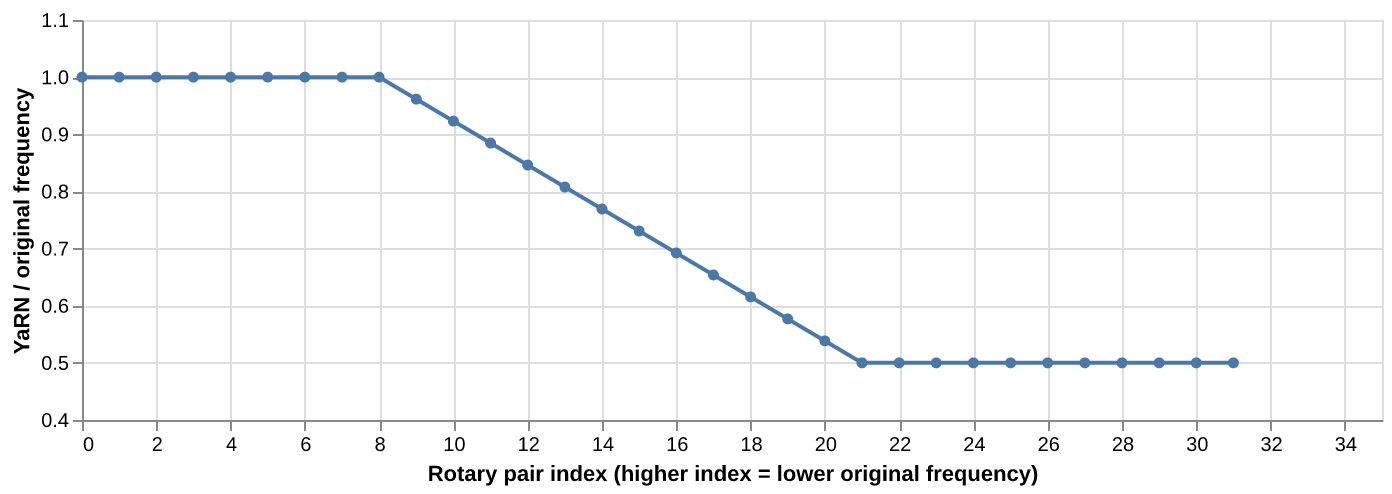

In [8]:
head_dimension = base_config.hidden_size // base_config.num_attention_heads
pair_indices = torch.arange(0, head_dimension, 2, device=DEVICE).float()
base_frequencies = 10000.0 ** (-pair_indices / head_dimension)

# These bounds use the ORIGINAL 2K window, not the extended 4K window.
ramp_start = math.floor(
    head_dimension
    * math.log(NATIVE_LENGTH / (32 * 2 * math.pi))
    / (2 * math.log(10000))
)
ramp_end = math.ceil(
    head_dimension * math.log(NATIVE_LENGTH / (1 * 2 * math.pi)) / (2 * math.log(10000))
)
frequency_pairs = torch.arange(head_dimension // 2, device=DEVICE).float()
interpolation_weight = ((frequency_pairs - ramp_start) / (ramp_end - ramp_start)).clamp(
    0, 1
)
expected_frequencies = (
    base_frequencies * (1 - interpolation_weight)
    + (base_frequencies / 2) * interpolation_weight
)

rotary_embedding = yarn_model.model.rotary_emb
check(
    "YaRN uses original 2K reference",
    torch.allclose(
        rotary_embedding.inv_freq, expected_frequencies, atol=1e-7, rtol=1e-6
    ),
    f"Frequency-ramp bounds {ramp_start} and {ramp_end}, extension factor 2",
)
check(
    "Configured YaRN rotary amplitude",
    abs(float(rotary_embedding.attention_scaling) - (1 + 0.1 * math.log(2))) < 1e-6,
    f"Rotary amplitude factor {float(rotary_embedding.attention_scaling):.8f}",
)

frequency_table = pd.DataFrame(
    {
        "Rotary pair": frequency_pairs.cpu().numpy(),
        "YaRN / original frequency": (expected_frequencies / base_frequencies)
        .cpu()
        .numpy(),
    }
)
frequency_chart = (
    alt.Chart(frequency_table)
    .mark_line(point=True)
    .encode(
        x=alt.X(
            "Rotary pair:Q",
            title="Rotary pair index (higher index = lower original frequency)",
        ),
        y=alt.Y("YaRN / original frequency:Q", scale=alt.Scale(domain=[0.4, 1.1])),
    )
    .properties(width=650, height=200)
)
display(chart_image(frequency_chart))


In [9]:
# Compare the optimized tail scorer with ordinary full-vocabulary logits.
with torch.inference_mode():
    probe_inputs = short_inputs[:1, :128]
    full_logits = (
        native_model(input_ids=probe_inputs, use_cache=False)
        .logits[:, -33:-1, :]
        .float()
    )
    full_head_losses = F.cross_entropy(
        full_logits.reshape(-1, full_logits.shape[-1]),
        probe_inputs[:, -32:].reshape(-1),
        reduction="none",
    ).view(1, 32)
    tail_head_losses = score_tail(native_model, probe_inputs, tail_length=32)

check(
    "Tail projection and next-token shift",
    torch.allclose(tail_head_losses, full_head_losses, atol=1e-5, rtol=1e-5),
    f"Max loss difference {(tail_head_losses - full_head_losses).abs().max().item():.3g}",
)

# BF16 backend tolerance screen at native 2K; always restore SDPA afterward.
sdpa_losses = score_tail(native_model, short_inputs).mean(1)
native_model.set_attn_implementation("eager")
try:
    eager_losses = score_tail(native_model, short_inputs).mean(1)
finally:
    native_model.set_attn_implementation("sdpa")

backend_max_nll_difference = (sdpa_losses - eager_losses).abs().max().item()
check(
    "SDPA versus eager numerical drift",
    backend_max_nll_difference < 0.02,
    f"Max per-article mean NLL difference {backend_max_nll_difference:.6f} nats/token; BF16 screen <0.02",
)
display(pd.DataFrame(checks))


,Check,Outcome,Detail
0,Identical pretrained weights,PASS,"134,515,008 parameters per model"
1,Identical scored targets,PASS,3 × 512 target IDs in every condition
2,YaRN uses original 2K reference,PASS,"Frequency-ramp bounds 8 and 21, extension fact..."
3,Configured YaRN rotary amplitude,PASS,Rotary amplitude factor 1.06931472
4,Tail projection and next-token shift,PASS,Max loss difference 0
5,SDPA versus eager numerical drift,PASS,Max per-article mean NLL difference 0.002087 n...


The native-2K backend screen allows a small BF16 difference. It does **not**
prove byte-identical outputs, cover every 4K condition, or approve a team-kernel
replacement. The primary G5-corpus experiment keeps eager attention throughout.


## 11. Run the four matched conditions

The three articles form one batch; each remains an independent sequence.
For each condition, score a warm-up pass, then measure three repeats with CUDA
events. The warm-up losses provide the quality result. Repeated timings do not
create additional quality samples.

The timing helper below keeps the experiment loop focused on the comparison.
It measures forward execution plus tail cross-entropy, with both BF16 model
copies resident. Downloads, loading and host-side finite checks are outside the
event interval. There is no KV-cache generation or training benchmark here.


In [10]:
def measure_tail_scoring(model, inputs, repeats=TIMING_REPEATS):
    """Return warm-up token losses and a warmed-up CUDA timing summary."""
    warmup_losses = score_tail(model, inputs)
    assert torch.isfinite(warmup_losses).all()
    torch.cuda.synchronize()

    elapsed_ms = []
    allocated_mib = []
    for repeat in range(repeats):
        torch.cuda.reset_peak_memory_stats()
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)
        start.record()
        measured_losses = score_tail(model, inputs)
        end.record()
        torch.cuda.synchronize()

        assert torch.isfinite(measured_losses).all()
        elapsed_ms.append(start.elapsed_time(end))
        allocated_mib.append(torch.cuda.max_memory_allocated() / 2**20)

    median_ms = float(np.median(elapsed_ms))
    timing = {
        "Median GPU ms": median_ms,
        "Min GPU ms": min(elapsed_ms),
        "Max GPU ms": max(elapsed_ms),
        "Input tokens per second": inputs.numel() / (median_ms / 1000),
        "Peak allocated MiB": max(allocated_mib),
    }
    return warmup_losses, timing


In [11]:
# Run ID, positional method, input length. D deliberately reuses C's YaRN config.
conditions = [
    ("A", "Original RoPE", NATIVE_LENGTH),
    ("B", "Original RoPE", LONG_LENGTH),
    ("C", "YaRN ×2", LONG_LENGTH),
    ("D", "YaRN ×2", NATIVE_LENGTH),
]
result_rows = []
timing_rows = []
token_losses = {}

for run_id, method, context_length in conditions:
    inputs = short_inputs if context_length == NATIVE_LENGTH else long_inputs
    losses, timing = measure_tail_scoring(models[method], inputs)
    assert inputs.shape[1] == context_length
    token_losses[run_id] = losses.cpu().numpy()

    for document, article_nll in zip(documents, losses.mean(1).tolist()):
        result_rows.append(
            {
                "Run": run_id,
                "Method": method,
                "Context": context_length,
                "Document": document["title"],
                "NLL": article_nll,
                "Perplexity": math.exp(article_nll),
                "Scored tokens": TAIL_LENGTH,
            }
        )
    timing_rows.append(
        {
            "Run": run_id,
            "Method": method,
            "Context": context_length,
            "Batch": DOCUMENT_COUNT,
            **timing,
        }
    )

results = pd.DataFrame(result_rows)
timings = pd.DataFrame(timing_rows)
summary = results.groupby(["Run", "Method", "Context"], as_index=False).agg(
    NLL=("NLL", "mean"),
    scored_tokens=("Scored tokens", "sum"),
)
summary["Perplexity"] = np.exp(summary["NLL"])
paired = results.pivot(index="Document", columns="Run", values="NLL")
paired["Long change C−B"] = paired["C"] - paired["B"]
paired["Short change D−A"] = paired["D"] - paired["A"]
paired["Extra prefix C−D"] = paired["C"] - paired["D"]

check(
    "All four real input lengths scored",
    len(results) == 4 * DOCUMENT_COUNT
    and set(summary["scored_tokens"]) == {DOCUMENT_COUNT * TAIL_LENGTH},
    "12 article-condition rows, 1,536 scored tokens per condition",
)
display(summary.round(6))


,Run,Method,Context,NLL,scored_tokens,Perplexity
0,A,Original RoPE,2048,2.470164,1536,11.824388
1,B,Original RoPE,4096,6.693264,1536,806.952112
2,C,YaRN ×2,4096,2.482160,1536,11.967088
3,D,YaRN ×2,2048,2.470355,1536,11.826650


## 12. Read the comparisons carefully

Lower NLL is better. Each panel shows one article; its vertical scale is
independent, so read the values rather than comparing the apparent line slopes
between panels. All methods within a panel score the same suffix.


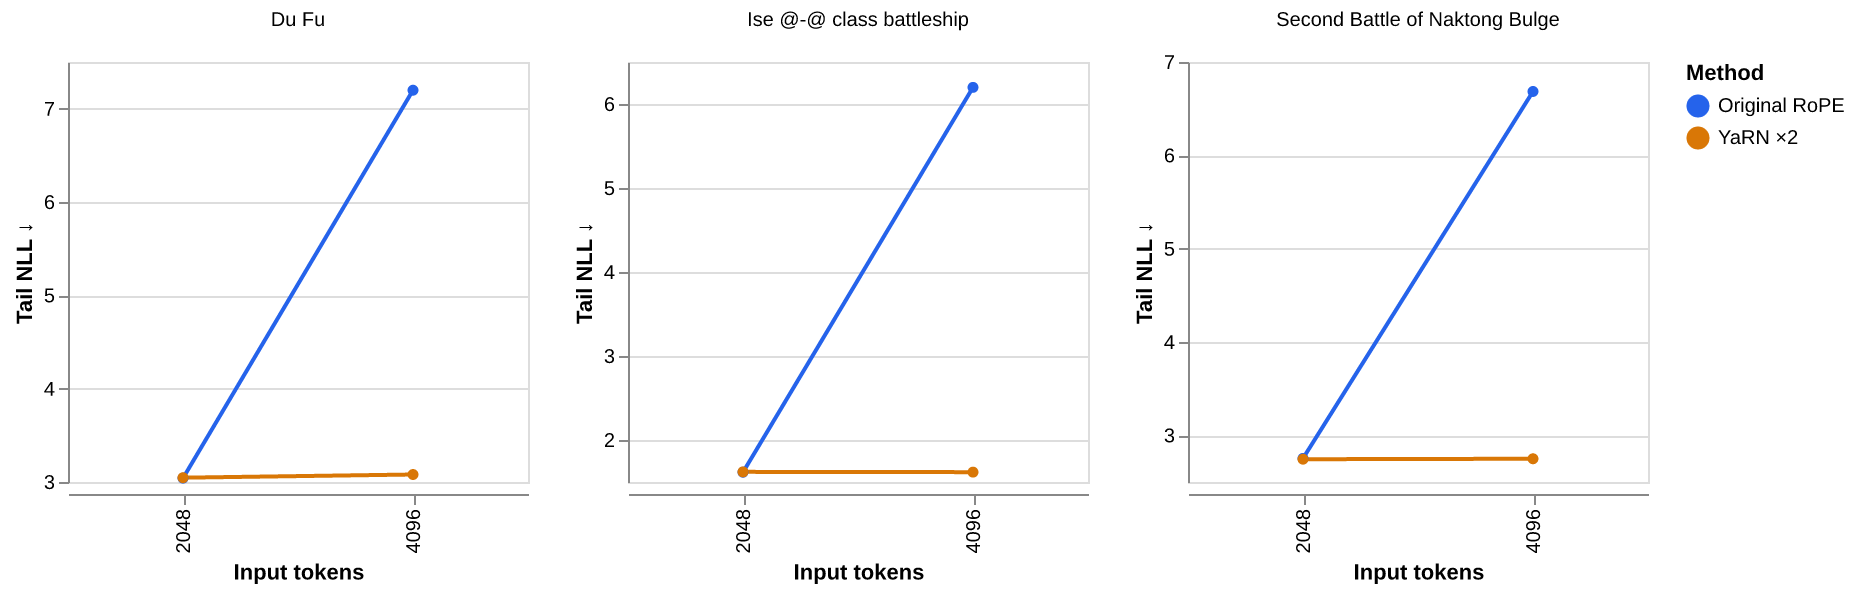

In [12]:
loss_chart = (
    alt.Chart(results)
    .mark_line(point=True)
    .encode(
        x=alt.X("Context:O", title="Input tokens"),
        y=alt.Y("NLL:Q", title="Tail NLL ↓", scale=alt.Scale(zero=False)),
        color=alt.Color(
            "Method:N",
            scale=alt.Scale(
                domain=["Original RoPE", "YaRN ×2"], range=["#2563eb", "#d97706"]
            ),
        ),
        tooltip=[
            "Document:N",
            "Method:N",
            "Context:O",
            alt.Tooltip("NLL:Q", format=".5f"),
        ],
    )
    .properties(width=230, height=210)
    .facet(column=alt.Column("Document:N", title=None))
    .resolve_scale(y="independent")
)
display(chart_image(loss_chart))


In [13]:
# Subtract matched article losses before averaging. This keeps the pairing visible.
long_delta = float((paired["C"] - paired["B"]).mean())
short_delta = float((paired["D"] - paired["A"]).mean())
long_vs_native = float((paired["C"] - paired["A"]).mean())
extra_prefix_delta = float((paired["C"] - paired["D"]).mean())
comparison_table = pd.DataFrame(
    [
        {"Comparison": "C−B: YaRN vs original at 4K", "Mean NLL change": long_delta},
        {"Comparison": "D−A: effect at 2K", "Mean NLL change": short_delta},
        {
            "Comparison": "C−A: overall candidate vs native",
            "Mean NLL change": long_vs_native,
        },
        {
            "Comparison": "C−D: extra prefix, YaRN fixed",
            "Mean NLL change": extra_prefix_delta,
        },
    ]
)
display(comparison_table.round(6))
print(
    f"C vs B: YaRN lowers 4K loss on {int((paired['C'] < paired['B']).sum())}/{DOCUMENT_COUNT} articles."
)
print(
    f"C vs D: the extra prefix changes perplexity by {100 * math.expm1(extra_prefix_delta):+.2f}% with YaRN fixed."
)
print(
    f"C vs A: the overall candidate changes perplexity by {100 * math.expm1(long_vs_native):+.2f}% versus native 2K."
)


,Comparison,Mean NLL change
0,C−B: YaRN vs original at 4K,-4.211104
1,D−A: effect at 2K,0.000191
2,C−A: overall candidate vs native,0.011996
3,"C−D: extra prefix, YaRN fixed",0.011805


C vs B: YaRN lowers 4K loss on 3/3 articles.
C vs D: the extra prefix changes perplexity by +1.19% with YaRN fixed.
C vs A: the overall candidate changes perplexity by +1.21% versus native 2K.


In the **recorded pilot**, YaRN sharply reduces the unscaled 4K failure and
largely restores native-window loss. C−D is slightly positive: the extra
prefix does not improve mean loss on these three suffixes. A restored loss
curve is not evidence that the model retrieves a distant fact when asked.
Three documents also do not establish a general short-context safety guarantee.


## 13. Keep performance separate from quality

Repeat the same three fixtures to test batching. This increases GPU work, not
the number of independent articles. We check the repeated fixtures' losses
against condition C and record peak **PyTorch allocated** memory, rather than
claiming total device memory. Larger batches need not be faster.


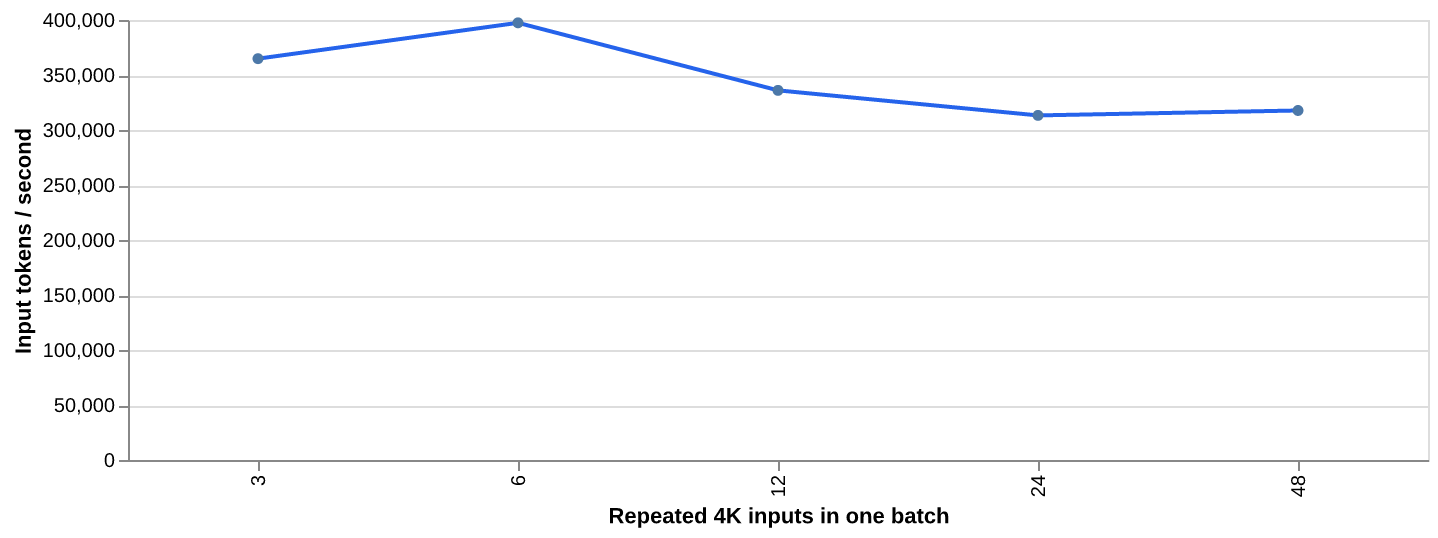

,Batch,Median GPU ms,Min GPU ms,Max GPU ms,Input tokens per second,Peak allocated MiB
0,3,33.68,33.57,33.94,364846.30,1247.86
1,6,61.84,61.48,62.06,397437.14,1968.27
2,12,146.27,146.01,146.82,336034.51,3409.95
3,24,313.81,313.71,314.14,313264.52,6290.69
4,48,618.77,618.71,618.86,317738.17,12053.93


,Run,Method,Context,Batch,Median GPU ms,Min GPU ms,Max GPU ms,Input tokens per second,Peak allocated MiB
0,A,Original RoPE,2048,3,17.40,17.39,17.45,353012.56,1247.76
1,B,Original RoPE,4096,3,33.70,33.63,33.83,364594.12,1247.77
2,C,YaRN ×2,4096,3,33.62,33.53,34.29,365529.80,1247.77
3,D,YaRN ×2,2048,3,17.62,17.60,17.73,348684.53,1247.77


In [14]:
batch_scaling_rows = []
for batch_size in BATCH_SIZES:
    assert batch_size % DOCUMENT_COUNT == 0
    batch_inputs = long_inputs.repeat(batch_size // DOCUMENT_COUNT, 1)
    batch_losses, batch_timing = measure_tail_scoring(yarn_model, batch_inputs)
    reference_losses = torch.tensor(token_losses["C"], device=DEVICE).mean(1)
    assert torch.allclose(
        batch_losses[:DOCUMENT_COUNT].mean(1), reference_losses, atol=0.02, rtol=0
    )
    batch_scaling_rows.append({"Batch": batch_size, **batch_timing})
    del batch_inputs, batch_losses

batch_scaling_results = pd.DataFrame(batch_scaling_rows)
throughput_chart = (
    alt.Chart(batch_scaling_results)
    .mark_line(point=True, color="#2563eb")
    .encode(
        x=alt.X("Batch:O", title="Repeated 4K inputs in one batch"),
        y=alt.Y("Input tokens per second:Q", title="Input tokens / second"),
        tooltip=[
            "Batch",
            alt.Tooltip("Median GPU ms:Q", format=".2f"),
            alt.Tooltip("Peak allocated MiB:Q", format=".1f"),
        ],
    )
    .properties(width=650, height=220)
)
display(chart_image(throughput_chart))
display(batch_scaling_results.round(2))
display(timings.round(2))


## 14. Check whether the broad result depends on precision

Reload both configurations from the **original checkpoint in FP32**, rather
than casting BF16-rounded weights back to FP32. Score the same four conditions
and targets with SDPA and highest float32 matmul precision. These are quality
checks; their runtime is not included in the BF16 performance table.


In [15]:
fp32_models = {
    "Original RoPE": AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=copy.deepcopy(base_config),
        dtype=torch.float32,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval(),
    "YaRN ×2": AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=copy.deepcopy(yarn_config),
        dtype=torch.float32,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval(),
}
precision_rows = []
for run_id, method, context_length in conditions:
    inputs = short_inputs if context_length == NATIVE_LENGTH else long_inputs
    fp32_losses = score_tail(fp32_models[method], inputs)
    assert torch.isfinite(fp32_losses).all()
    for document, article_nll in zip(documents, fp32_losses.mean(1).tolist()):
        precision_rows.append(
            {
                "Run": run_id,
                "Method": method,
                "Context": context_length,
                "Document": document["title"],
                "NLL": article_nll,
            }
        )

del fp32_models, fp32_losses
torch.cuda.empty_cache()
precision_results = pd.DataFrame(precision_rows)
precision_summary = precision_results.groupby(
    ["Run", "Method", "Context"], as_index=False
).agg(NLL=("NLL", "mean"))
precision_summary["Perplexity"] = np.exp(precision_summary["NLL"])
display(precision_summary.round(6))


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

,Run,Method,Context,NLL,Perplexity
0,A,Original RoPE,2048,2.468912,11.809586
1,B,Original RoPE,4096,6.697379,810.279388
2,C,YaRN ×2,4096,2.482499,11.971137
3,D,YaRN ×2,2048,2.469834,11.820482


## 15. Save enough evidence to audit a run

The CSVs retain individual articles as well as means. The arrays retain every
token loss; fixtures retain exact input IDs and hashes. The manifest records
revisions, rotary settings, software, hardware and checks. Fresh files stay
under the output directory and do not replace the historical submission data.


In [16]:
manifest = {
    "experiment": "SmolLM-135M inference-only YaRN2 2K/4K",
    "scope": "exploratory_wikitext_pilot",
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "dataset_id": DATASET_ID,
    "dataset_revision": DATASET_REVISION,
    "dataset_config": "wikitext-103-raw-v1",
    "dataset_split": "test",
    "selection": "first three complete articles with at least 4096 tokens; first 4096 tokens of each",
    "short_input": "last 2048 tokens of each fixed 4096-token input",
    "scoring": "same last512 target IDs; full input; last513 logit rows with final row dropped",
    "dtype": str(DTYPE),
    "attention_backend": "sdpa",
    "batch_size": DOCUMENT_COUNT,
    "native_rope": base_config.rope_parameters,
    "yarn_rope": yarn_config.rope_parameters,
    "yarn_attention_factor": float(rotary_embedding.attention_scaling),
    "seed": 1234,
    "hardware": hardware,
    "versions": {
        package: importlib.metadata.version(package)
        for package in [
            "torch",
            "transformers",
            "datasets",
            "huggingface-hub",
            "pandas",
            "altair",
            "vl-convert-python",
        ]
    },
    "checks": checks,
    "backend_max_nll_difference": backend_max_nll_difference,
    "long_mean_nll_change": long_delta,
    "short_mean_nll_change": short_delta,
    "long_vs_native_nll_change": long_vs_native,
    "extra_prefix_nll_change": extra_prefix_delta,
    "executed_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "precision_sensitivity": precision_summary.to_dict(orient="records"),
    "batch_scaling": batch_scaling_results.to_dict(orient="records"),
    "timing_scope": "GPU forward plus tail cross-entropy; one shape warmup; 3 timed repeats; both BF16 models resident",
}

for filename, table in {
    "document_results.csv": results,
    "summary.csv": summary,
    "paired_changes.csv": paired.reset_index(),
    "timings.csv": timings,
    "batch_scaling.csv": batch_scaling_results,
    "fp32_sensitivity.csv": precision_results,
}.items():
    table.to_csv(ARTIFACT_DIR / filename, index=False)

(ARTIFACT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
(ARTIFACT_DIR / "input_fixtures.json").write_text(json.dumps(documents, indent=2))
np.savez_compressed(ARTIFACT_DIR / "per_token_nll.npz", **token_losses)
for filename, chart in {
    "loss_chart.png": loss_chart,
    "frequency_schedule.png": frequency_chart,
    "batch_scaling.png": throughput_chart,
}.items():
    (ARTIFACT_DIR / filename).write_bytes(vlc.vegalite_to_png(chart.to_dict(), scale=2))

print(f"Fresh evidence written to: {ARTIFACT_DIR.relative_to(Path.cwd())}/")
display(JSON(manifest))


Fresh evidence written to: out/context_extension_pilot/


<IPython.core.display.JSON object>

## 16. What should happen after this small-model test?

The proposal is a **controlled 2× extension trial on the approved team checkpoint**,
with its own tokenizer, rotary convention, original window and evaluation data.
Keep the approved eager attention path and other settings fixed for that first
comparison. Repeat A/B/C/D on a larger, relevant held-out sample and inspect
short-context regressions by domain and language. Add distant-fact retrieval
only after verifying that the short version of the task is solvable.

If continued training is needed, TSAI must first agree the target length,
long-document source, retained short-context mixture and compute budget.
This inference-only pilot provides no optimum learning rate, training mixture
or production context schedule. Its role is to make the proposed positional
change testable and explain what the present evidence does and does not show.

### Sources and data attribution

- [G5 proposal and primary corpus result](../docs/long_context_plan.md)
- [Original pilot log and provenance](../results/context_extension/PILOT_TEST_LOG.md)
- [SmolLM checkpoint at the pinned revision](https://huggingface.co/HuggingFaceTB/SmolLM-135M/tree/1d461723eec654e65efdc40cf49301c89c0c92f4)
- [WikiText at the pinned revision](https://huggingface.co/datasets/Salesforce/wikitext/tree/b08601e04326c79dfdd32d625aee71d232d685c3)
- [Peng et al., YaRN, ICLR 2024](https://proceedings.iclr.cc/paper_files/paper/2024/file/874a4d89f2d04b4bcf9a2c19545cf040-Paper-Conference.pdf)

WikiText derives from Wikipedia. Preserve the source attribution and applicable
share-alike terms when redistributing exact fixtures. This is a three-article
English pilot with unknown pretraining overlap, not multilingual validation or
an official TSAI team-model run.
